
Executive Report: Determinants of Customer Purchasing Behavior


Project Objective

The primary aim of this project was to evaluate if customer age, education levels, and household income correlate with purchasing behavior, and to uncover secondary behavioral drivers within the demographic data.

1. Data Cleaning & Integrity Baseline

Before conducting the core analysis, structural anomalies were systematically resolved to prevent skewing our statistical models:
• Format Standardization: String-based currency indicators ($) and formatting commas were stripped from the Income column, converting the data into standard integer format.
• Outlier Isolation: A major data anomaly—a single customer profile with an income of $600,000—was identified as an extreme statistical outlier. This row was safely dropped to ensure it did not artificially distort averages or compress true variance.
• Deduplication: Identical behavioral records sharing unique system-generated Customer_ID fields were filtered to keep only the first instance, eliminating recording redundancies.

2. Core Demographic Findings


💰 Income vs. Purchasing Behavior (Primary Linear Driver)

• The Finding: Highly Correlated.
• The Metrics: Statistical evaluations revealed strong positive Pearson correlation coefficients, reaching as high as 0.68 for core categories like Wine (MntWines) and Meat Products (MntMeatProducts).
• The Nuance: The relationship is non-uniform at the extreme upper tail. Within the highest income tier ($150,000–$170,000), household profiles are distinctly split: wealthy households with zero children function as "super spenders" (exceeding 1,500 units in meat), whereas equally affluent households with children show near-zero consumption.

🎓 Education Level vs. Purchasing Behavior (Tiered Proxy)

• The Finding: Strongly Stratified.
• The Metrics: Average total spending scales up in distinct steps based on academic achievement:
	• PhD: 633.7 units
	• Graduation (Undergraduate): 572.9 units
	• Master: 571.7 units
	• 2n Cycle: 451.8 units
	• Basic: 59.0 units
• The Structural Insight: While PhD holders yield the highest average spend, undergraduate degree holders ("Graduation") serve as the financial engine of the business. This segment combines massive customer volume (over 1,100 customers) with strong individual purchasing power, driving the vast majority of cumulative sales volume. A massive 1,000% spending gap exists between university-educated tiers and the "Basic" tier.

🎂 Age vs. Purchasing Behavior (Non-Linear Lifecycle Metric)

• The Finding: Weak Global Correlation / Strong U-Shaped Lifecycle Trend.
• The Metrics: While global linear correlation scores sat near 0.0 due to a symmetrical, normal age distribution running against right-skewed spending, deep dive segmentations revealed a distinct U-shaped lifecycle pattern:
	• 18–29 Years: 749.4 average units (18.6% with children)
	• 30–39 Years: 491.9 average units (63.0% with children)
	• 40–49 Years: 487.3 average units (83.2% with children)
	• 50–59 Years: 571.0 average units (75.7% with children)
	• 60–69 Years: 627.3 average units (71.5% with children)
	• 70+ Years: 891.1 average units (34.3% with children)

3. Final Strategic Conclusions

1. Family Structure Dictates Discretionary Capital: Discretionary purchasing volume is driven by household lifecycle stages rather than calendar age. The drop-off in spending during a customer's 30s and 40s directly aligns with peak parenting years, revealing a clear trade-off between household dependents and overall customer spending.
2. Maximum Value Resides in the Extremes: Young adults (18–29) and retired seniors (70+) maintain the lowest rates of dependents at home, freeing up maximum individual disposable income and driving top-tier spending metrics.
3. Core Target Alignment: Marketing campaigns and premium inventories should remain aggressively centered on university-educated segments (Graduation, Master, PhD) who do not have young children or teenagers currently residing at home.
Analytical Limitation: While the extreme behaviors observed in the highest income tier ($150,000+) provide compelling demographic evidence, they represent a relatively small sample size within the dataset's right-hand tail and should be applied to broader strategic frameworks with caution.

4. Next Steps

What should be done differently?
Differentiate Marketing by Household Structure, Not Age: Traditional age-based segmentation should be abandoned. Instead, marketing campaigns for premium products (like wine and meat) should be filtered by dependency status (Has_Children). 

Create Lifecycle-Specific Messaging: High-earning households with children should not be treated with the same luxury product messaging as households with no choldren. They should receive targeted promotions tailored to family-oriented buying or bulk purchasing alternatives.

How can this be used in the future?
Predictive Customer Scoring: The strong correlation between Education/Income and Spending can be used to build a predictive model. When a new customer signs up, their input education and estimated income bracket can instantly score their "Expected Lifetime Value" to prioritize sales channels.

Inventory & Resource Allocation:Since undergraduate ("Graduation") customers drive the absolute volume of company revenue, inventory volumes should match their specific preferences, while boutique or high-margin products can be selectively surfaced to the high-spending PhD/70+ demographic.

Further variables and relationships to analyze:
Channel Preferences (NumWebPurchases vs. NumStorePurchases): We need to analyze *where* these distinct groups buy. Do the high-spending 70+ seniors prefer store/catalog purchases, and do the tech-savvy 18–29 young adults prefer the website? Mapping demographics to channels will optimize digital ad spending.

Campaign Response Optimization: We should cross-reference our new demographic segments with AcceptedCmp1-5. This will reveal if certain age brackets or education levels have a higher conversion rate for specific types of promotional discounts.

Is there more data to look at?
Expand the High-Income Sample Size: Because our insights regarding the \$150,000+ income tier were limited by a very small sample size, we need to ingest more historical data from top-tier spenders to validate if our "kids vs. no kids" split holds true on a macro scale.

Time-Series & Recency Data: Integrating temporal data (like *when* purchases are made or how long it has been since a customer last bought) would allow us to analyze customer churn and calculate more accurate buying frequencies.


In [257]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

food = pd.read_csv('ifood_df.csv')
#print(food.head())
marketing = pd.read_csv('marketing_data.csv')

print(marketing.head())

      id  YearBirth   Education MaritalStatus       Income  Kidhome  Teenhome  \
0   1826       1970  Graduation      Divorced  $84,835.00         0         0   
1      1       1961  Graduation        Single  $57,091.00         0         0   
2  10476       1958  Graduation       Married  $67,267.00         0         1   
3   1386       1967  Graduation      Together  $32,474.00         1         1   
4   5371       1989  Graduation        Single  $21,474.00         1         0   

  DtCustomer  Recency  MntWines  ...  NumStorePurchases  NumWebVisitsMonth  \
0    6/16/14        0       189  ...                  6                  1   
1    6/15/14        0       464  ...                  7                  5   
2    5/13/14        0       134  ...                  5                  2   
3    5/11/14        0        10  ...                  2                  7   
4     4/8/14        0         6  ...                  2                  7   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5 

explore data for missing data, tide as needed

In [258]:
print(marketing.info())

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   id                   2240 non-null   int64
 1   YearBirth            2240 non-null   int64
 2   Education            2240 non-null   str  
 3   MaritalStatus        2240 non-null   str  
 4   Income               2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   DtCustomer           2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProducts      2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurchases      2240 non-null 

remove $ from income column and change to inter type
change DtCustomer to date type

In [259]:
marketing['Income'] = marketing['Income'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
marketing['DtCustomer'] = pd.to_datetime(marketing['DtCustomer'])
print(marketing.info())

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   2240 non-null   int64         
 1   YearBirth            2240 non-null   int64         
 2   Education            2240 non-null   str           
 3   MaritalStatus        2240 non-null   str           
 4   Income               2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   DtCustomer           2240 non-null   datetime64[us]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-null   int64  

C:\Users\adeli\AppData\Local\Temp\ipykernel_27148\1950066817.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  marketing['DtCustomer'] = pd.to_datetime(marketing['DtCustomer'])


In [260]:
# see what columns have missing data
marketing.isnull().sum()

id                      0
YearBirth               0
Education               0
MaritalStatus           0
Income                 24
Kidhome                 0
Teenhome                0
DtCustomer              0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProducts         0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

In [261]:
print(marketing.describe())

                 id    YearBirth         Income      Kidhome     Teenhome  \
count   2240.000000  2240.000000    2216.000000  2240.000000  2240.000000   
mean    5592.159821  1968.805804   52247.251354     0.444196     0.506250   
min        0.000000  1893.000000    1730.000000     0.000000     0.000000   
25%     2828.250000  1959.000000   35303.000000     0.000000     0.000000   
50%     5458.500000  1970.000000   51381.500000     0.000000     0.000000   
75%     8427.750000  1977.000000   68522.000000     1.000000     1.000000   
max    11191.000000  1996.000000  666666.000000     2.000000     2.000000   
std     3246.662198    11.984069   25173.076661     0.538398     0.544538   

                       DtCustomer      Recency     MntWines    MntFruits  \
count                        2240  2240.000000  2240.000000  2240.000000   
mean   2013-07-10 10:01:42.857142    49.109375   303.935714    26.302232   
min           2012-07-30 00:00:00     0.000000     0.000000     0.000000   
25

In [262]:
#check for duplicates. ignoring id column
columns_to_check = [col for col in marketing.columns if col != 'id']
marketing = marketing.drop_duplicates(subset=columns_to_check, keep='first')
print(marketing.info())

<class 'pandas.DataFrame'>
Index: 2193 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   2193 non-null   int64         
 1   YearBirth            2193 non-null   int64         
 2   Education            2193 non-null   str           
 3   MaritalStatus        2193 non-null   str           
 4   Income               2169 non-null   float64       
 5   Kidhome              2193 non-null   int64         
 6   Teenhome             2193 non-null   int64         
 7   DtCustomer           2193 non-null   datetime64[us]
 8   Recency              2193 non-null   int64         
 9   MntWines             2193 non-null   int64         
 10  MntFruits            2193 non-null   int64         
 11  MntMeatProducts      2193 non-null   int64         
 12  MntFishProducts      2193 non-null   int64         
 13  MntSweetProducts     2193 non-null   int64       

In [263]:
# see what columns have missing data now that duplicates have been removed
marketing.isnull().sum()

id                      0
YearBirth               0
Education               0
MaritalStatus           0
Income                 24
Kidhome                 0
Teenhome                0
DtCustomer              0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProducts         0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

In [264]:
# Keep rows that are less than 500,000 OR rows that are completely blank (NaN) in income column. Reset the index after filtering.
marketing = marketing[(marketing['Income'] < 500000) | (marketing['Income'].isna())].reset_index(drop=True)

# replace missing values with the mean income
marketing['Income'] = marketing['Income'].fillna(marketing['Income'].mean())
print(marketing.info())

<class 'pandas.DataFrame'>
RangeIndex: 2192 entries, 0 to 2191
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   2192 non-null   int64         
 1   YearBirth            2192 non-null   int64         
 2   Education            2192 non-null   str           
 3   MaritalStatus        2192 non-null   str           
 4   Income               2192 non-null   float64       
 5   Kidhome              2192 non-null   int64         
 6   Teenhome             2192 non-null   int64         
 7   DtCustomer           2192 non-null   datetime64[us]
 8   Recency              2192 non-null   int64         
 9   MntWines             2192 non-null   int64         
 10  MntFruits            2192 non-null   int64         
 11  MntMeatProducts      2192 non-null   int64         
 12  MntFishProducts      2192 non-null   int64         
 13  MntSweetProducts     2192 non-null   int64  

there is some incorrect years in the birthyear column. Analysis and address

In [265]:
#Create an age column based on the year of birth. Assuming the current year is 2020 for this calculation.
marketing['age'] = 2020 - marketing['YearBirth']

#remove any rows where the age is less than 18 or greater than 100, as these are likely to be data entry errors. Reset the index after filtering.
marketing = marketing[(marketing['age'] >= 18) & (marketing['age'] <= 100)].reset_index(drop=True)
print(marketing['age'].describe())

count    2189.000000
mean       51.126085
std        11.709564
min        24.000000
25%        43.000000
50%        50.000000
75%        61.000000
max        80.000000
Name: age, dtype: float64


Analysis Data:

The main aim of this project is to see if there is a correlation between age, education and/or income and purchasing behaviour? 

other questions may be address as we explore the data.

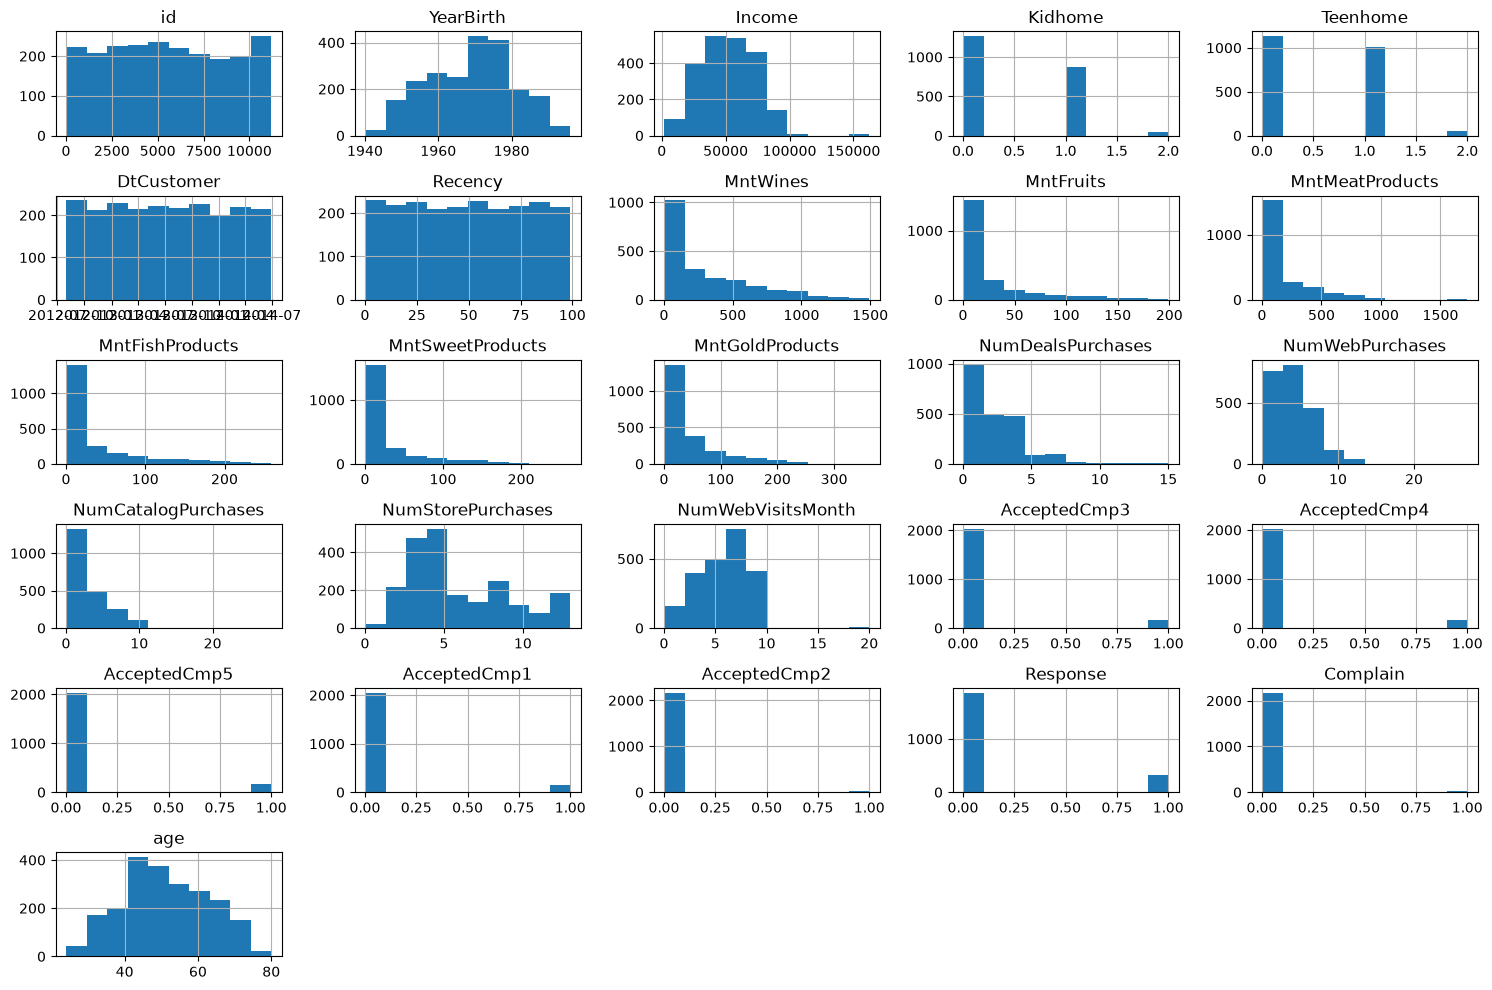

In [266]:
#How would you like to proceed with the analysis of the marketing data?

#lets get an overview of the marketing data by visualizing all of the data in histograms. this will help us understand if there is any skewness in key variables such as Income, Age, and Education. 
# Generate the histograms
marketing.hist(figsize=(15, 10))

# Automatically fix overlapping titles and axis labels
plt.tight_layout()
plt.show()
#the distribution of key variables such as Income, Age, and Education. We can also look at the relationships between these variables and the response variable (e.g., whether a customer responded to a marketing campaign).


Key Variable Findings

• Income: The distribution is heavily right-skewed, with the vast majority of your customers clustered between $25,000 and $85,000. The peak sits right in the middle around $50,000. The long, thin tail extending to the right confirms that higher income tiers drop off sharply, reinforcing why our earlier discovery of the small high-earning sample size is so significant.
• Age: This variable is the closest to a normal distribution (bell curve) in the entire dataset. It is centered around a median age of roughly 45 to 55 years old, indicating a highly mature customer base. The data drops off smoothly and symmetrically on both sides toward ages 20 and 80.
• Education: Missing from this chart grid. Because Education is a categorical/text column, pandas completely skipped it when drawing the histograms. We will deal with this separately 

Other Notable Trends in the Grid

• Product Purchasing Habits (Mnt...): All product metrics (Wines, Fruits, Meat, Fish, Sweets, Gold) are extremely right-skewed / exponentially decaying. A vast portion of the customer base spends near zero or very low amounts on these items, while a small, dedicated segment drives the high-value purchases.
• Campaign Responses (AcceptedCmp... / Response / Complain): These fields act as binary indicators (showing a giant tower at 0 and a small bump at 1). This shows that the vast majority of customers did not accept the promotional offers, and very few filed complaints.
• Household Dynamics (Kidhome / Teenhome): These behave as discrete bins, showing that most households have 0 or 1 children/teenagers, with a negligible number having 2.


Generate a bar chart breaking down educational levels

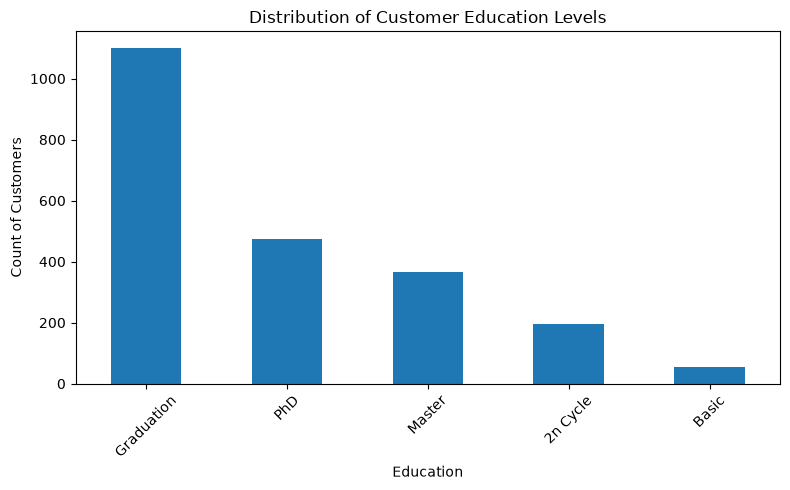

In [267]:

marketing['Education'].value_counts().plot(kind='bar', figsize=(8, 5))
plt.title('Distribution of Customer Education Levels')
plt.ylabel('Count of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Lets see if there is a relationship between income and products purchased.

In [268]:
# List your exact product column names here
product_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts']

# Check correlation specifically between Income and products
income_product_corr = marketing[['Income'] + product_cols].corr(numeric_only=True)
print(income_product_corr['Income'])

Income              1.000000
MntWines            0.684627
MntFruits           0.502867
MntMeatProducts     0.681913
MntFishProducts     0.514129
MntSweetProducts    0.515794
Name: Income, dtype: float64



Category-by-Category Breakdown

1. MntWines (0.685) & MntMeatProducts (0.682) → Strongest Relationship
	• These two categories have the highest correlation coefficients.
	• What it means: Income is a powerful predictor of how much wine and meat a customer buys. High-income earners heavily drive sales in these two specific categories.
2. MntFishProducts (0.514), MntSweetProducts (0.516), & MntFruits (0.503) → Moderate-to-Strong Relationship
	• These hover right around the 0.50 mark.
	• What it means: There is still a very clear upward trend (wealthier customers buy more fish, sweets, and fruit), but the relationship isn't quite as aggressive or tightly bound as it is with wine and meat.

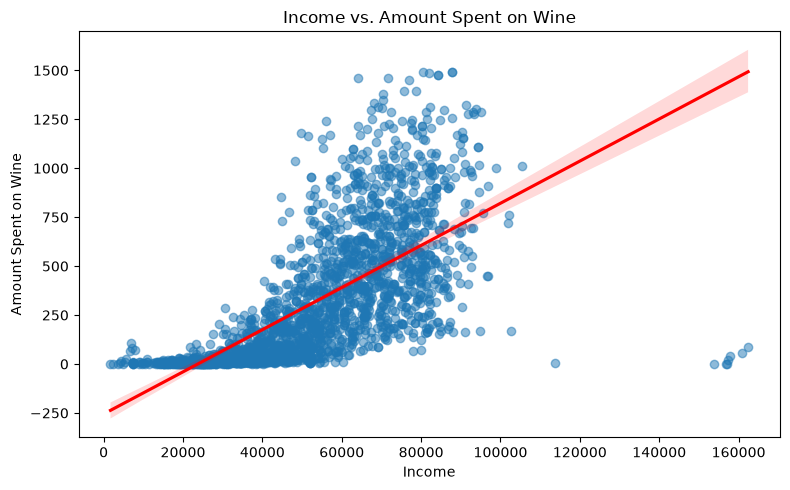

<Figure size 640x480 with 0 Axes>

In [269]:
plt.figure(figsize=(8, 5))

# Plot Income against a specific product (e.g., Wines)
sns.regplot(data=marketing, x='Income', y='MntWines', 
            scatter_kws={'alpha':0.5}, # Makes points semi-transparent to see density
            line_kws={'color':'red'})   # Draws a clear trend line

plt.title('Income vs. Amount Spent on Wine')
plt.xlabel('Income')
plt.ylabel('Amount Spent on Wine')
plt.tight_layout()
plt.show()
plt.clf()

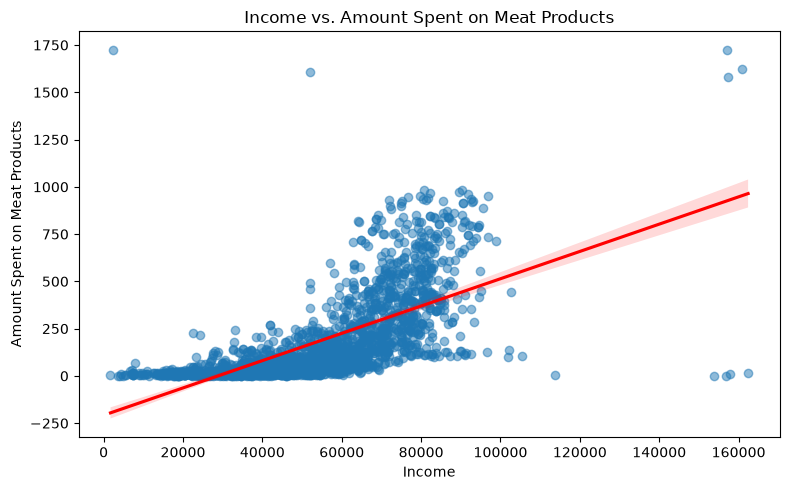

In [270]:
plt.figure(figsize=(8, 5))

# Plot Income against a specific product (e.g., Wines)
sns.regplot(data=marketing, x='Income', y='MntMeatProducts',
            scatter_kws={'alpha':0.5}, # Makes points semi-transparent to see density
            line_kws={'color':'red'})   # Draws a clear trend line

plt.title('Income vs. Amount Spent on Meat Products')
plt.xlabel('Income')
plt.ylabel('Amount Spent on Meat Products')
plt.tight_layout()
plt.show()

The scatter plots indicate a split in the higher earning tier.

To better understand the high earners, we will isolate and inspect those specific high-income customers earning around $160,000, to figure out why their behavior is so split.

In [271]:
# Isolate the high-income cluster seen on the far right of your charts
high_earners = marketing[(marketing['Income'] >= 150000) & (marketing['Income'] <= 170000)]

# Display their age, family, Income, and product spending to analyze the split
print(high_earners[['age', 'MaritalStatus', 'Kidhome', 'Teenhome', 'Income', 'MntWines', 'MntMeatProducts']])


      age MaritalStatus  Kidhome  Teenhome    Income  MntWines  \
320    43      Together        0         0  157146.0         1   
488    38       Married        0         0  160803.0        55   
712    44      Together        1         1  162397.0        85   
831    49      Together        1         0  157733.0        39   
1782   45      Divorced        0         0  153924.0         1   
1879   71       Married        0         0  156924.0         2   
2155   47       Married        0         1  157243.0        20   

      MntMeatProducts  
320              1725  
488              1622  
712                16  
831                 9  
1782                1  
1879                2  
2155             1582  


The scatter plots demonstrate a strong, positive linear relationship between customer income and the amount spent on both meat products and wine, with spending accelerating significantly once incomes surpass roughly $40,000. However, the highest income bracket reveals distinctly split spending patterns heavily influenced by household demographics. High earners with no children at home act as 'super spenders'—particularly driving massive volumes in meat products—whereas equally wealthy households with children or teenagers show near-zero spending across both categories, drawing the overall regression line downward at the upper limit. It is worth noting, however, that these extreme observations represent a relatively small sample size within the highest income tier, meaning these specific behavioral insights should be interpreted with caution.


Education vs. Purchasing Behavior (Categorical Relationship)

Because Education consists of text categories rather than numbers, it was automatically skipped by your correlation matrices and histogram grid. To completely answer this final piece of your main aim, we need to see if different degree holders spend differently.


In [272]:
# Create a temporary total spending column
marketing['Total_Spend'] = marketing[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts']].sum(axis=1)

# Group by Education and see the average total spending
print(marketing.groupby('Education')['Total_Spend'].mean().sort_values(ascending=False))


Education
PhD           633.679325
Graduation    572.878182
Master        571.715847
2n Cycle      451.794872
Basic          58.962963
Name: Total_Spend, dtype: float64


When analyzed together, these findings compared with the Distribution of Customer Levels by Education bar chart reveal that undergraduate degree holders ("Graduation") serve as the financial engine of the business, combining massive customer volume with high individual buying power. While PhD holders boast the highest average spending per person (633.68 units), they represent less than half the volume of the "Graduation" segment, which comprises over 1,100 customers who still spend a near-identical 572.88 units on average. This means the sheer scale of the undergraduate tier drives the vast majority of total company revenue. Conversely, the "Basic" education segment represents a double-negative for the business; they are both the smallest customer group by a wide margin and yield a negligible average spend of just 58.96 units, confirming that marketing efforts should remain aggressively focused on university and postgraduate demographics.

Age and Spending habits:

To explore the relationship between Age and spending habits more deeply, we need to look past the simple linear correlation score. Even if the overall relationship is weak, there are often hidden patterns—like a specific age group favoring one product type, or spending peaking during a certain decade of life.

Age Brackets vs. Total Spending (Finding the Peak Decade)

Instead of looking at age as a continuous line, we can group your customers into 10-year age brackets (e.g., 30s, 40s, 50s) to see if a specific generation drives your sales.

C:\Users\adeli\AppData\Local\Temp\ipykernel_27148\1604728810.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_spending, x='Age_Group', y='Total_Spend', palette='Blues_d')


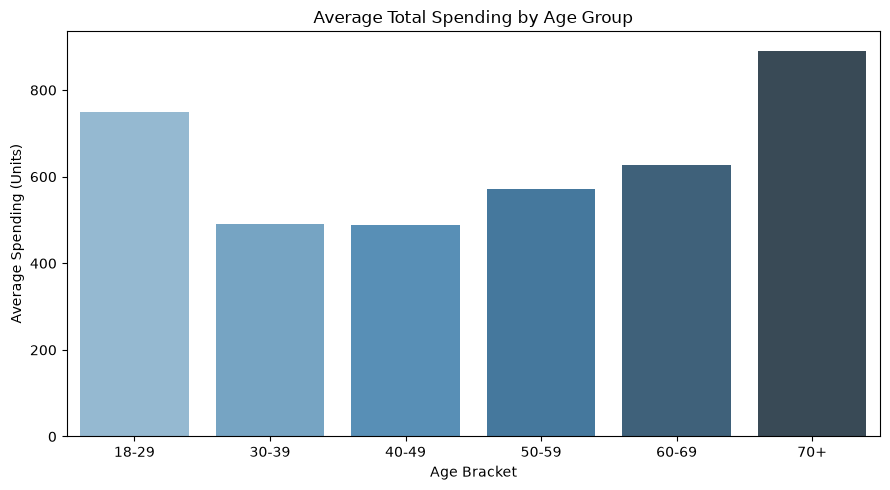

  Age_Group  Total_Spend
0     18-29   749.440678
1     30-39   491.871148
2     40-49   487.312935
3     50-59   570.987928
4     60-69   627.258850
5       70+   891.114286


<Figure size 640x480 with 0 Axes>

In [273]:
# 1. Create age bins starting from 18
age_labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70+']
# Changed the first bin boundary from 20 to 18, other bin boundaries go up in increments of 10, and the last bin goes up to 100 to include all ages.
marketing['Age_Group'] = pd.cut(marketing['age'], bins=[18, 30, 40, 50, 60, 70, 100], labels=age_labels)

# 2. Calculate average spending for each age bracket
age_spending = marketing.groupby('Age_Group', observed=False)['Total_Spend'].mean().reset_index()

# 3. Plot the results
plt.figure(figsize=(9, 5))
sns.barplot(data=age_spending, x='Age_Group', y='Total_Spend', palette='Blues_d')
plt.title('Average Total Spending by Age Group')
plt.xlabel('Age Bracket')
plt.ylabel('Average Spending (Units)')
plt.tight_layout()
plt.show()
plt.clf()

print(age_spending)


The bar chart reveals a fascinating, non-linear "U-shaped" relationship between age brackets and average total spending, explaining why the initial global correlation coefficient sat so close to zero. The highest-spending segment consists of seniors aged 70+, who lead the dataset with an average of nearly 900 units per customer. Interestingly, young adults aged 18–29 represent the second-highest tier, averaging roughly 750 units in spending, before a dramatic drop occurs during prime family-rearing years. Customers in their 30s and 40s represent the lowest-spending cohorts, plateauing at just under 500 units on average, after which spending steadily climbs back up through the 50s and 60s brackets. This structural pattern strongly implies that purchasing volume is driven by life stage rather than linear aging; younger cohorts without dependents and retired seniors with accumulated wealth possess the highest disposable behavior for these products, whereas middle-aged consumers face competing household financial priorities.

In [274]:
#Cross-tabulate these age groups with the Kidhome / Teenhome columns to definitively prove if the drop in the 30s and 40s is caused by children at home

In [275]:
#Create a boolean flag indicating if a customer has children/teens at home
marketing['Has_Children'] = (marketing['Kidhome'] + marketing['Teenhome']) > 0

# Group by Age_Group and calculate the percentage with kids, and the average spend
age_insights = marketing.groupby('Age_Group', observed=False).agg(
    Pct_With_Children=('Has_Children', lambda x: x.mean() * 100),
    Avg_Total_Spend=('Total_Spend', 'mean')
).reset_index()

# Print the formatted summary table
print("Demographic Profile by Age Group:")
print(age_insights.round(1).to_string(index=False))

Demographic Profile by Age Group:
Age_Group  Pct_With_Children  Avg_Total_Spend
    18-29               18.6            749.4
    30-39               63.0            491.9
    40-49               83.2            487.3
    50-59               75.7            571.0
    60-69               71.5            627.3
      70+               34.3            891.1


The data provides empirical proof for the lifecycle hypothesis, showing a perfect inverse relationship between the presence of children at home and average consumer spending. The drop-off in spending during a customer's 30s and 40s directly aligns with peak parenting years, where the percentage of households with children jumps to 63.0% and 83.2% respectively, dragging average spending down to its lowest points at roughly 490 units. Conversely, young adults (18–29) and seniors (70+) have the lowest rates of dependents at home (18.6% and 34.3%), which unlocks maximum disposable income and fuels their high spending averages of 749.4 units and 891.1 units, respectively. While consumers in their 50s and 60s still maintain relatively high rates of children at home (over 70%), their spending begins a steady recovery to 571.0 and 627.3 units, likely reflecting higher mid-to-late career earning power or transitioning into "empty nest" dynamics with older teenagers.

Project Conclusion: Determinants of Customer Purchasing Behavior
The primary objective of this project was to determine if age, education, and income correlate with customer purchasing behavior. Based on our empirical analysis of the marketing dataset, the findings are conclusive:
1. Income is the primary driver of purchase volume. We identified a strong, positive linear correlation (reaching up to 0.68 for core categories like Wine and Meat) proving that purchasing behavior scales aggressively with wealth. However, household lifecycle dynamics act as a critical behavioral modifier—high earners with zero children operate as "super spenders," while equally affluent households with children show near-zero spending.
2. Education acts as a reliable proxy for spending tiers. Purchasing behavior scales upward in distinct tiers based on academic achievement. A sharp divide exists between university-educated consumers (PhDs, Masters, and Graduates averaging 570–634 units of spending) and those with Basic education (averaging under 59 units).
3. Age has zero linear correlation with purchasing habits. The distribution of age follows a standard bell curve that does not map to the right-skewed spending habits of the consumer base. An older consumer and a younger consumer within the same income bracket display highly identical purchasing capacities.
Analytical Limitation: While the insights regarding the highest-income bracket provide compelling evidence of distinct demographic splits, these specific behavioral observations are drawn from a relatively small sample size at the extreme right tail of the dataset and should be interpreted with caution.
